# CS 746 | Statistical Analysis

Two-sided comparisons of benign and malicious DNS-over-HTTPS flow features. Source: CIRA-CIC-DoHBrw-2020; selected Cloudflare and DNSCat2 subsets.

## 1. Load data

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
DATA_DIR = Path.cwd()
benign_path = DATA_DIR / "normal_doh_traffic_cloudflare_server (1).csv"
malicious_path = DATA_DIR / "dnscat2_data_4 (1).csv"
for path in (benign_path, malicious_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing source dataset: {path}")
benign = pd.read_csv(benign_path)
malicious = pd.read_csv(malicious_path)
benign["traffic_class"] = "Benign"
malicious["traffic_class"] = "Malicious"
df = pd.concat([benign, malicious], ignore_index=True)
features = [c for c in df.select_dtypes(include="number") if c != "is_doh" and df[c].nunique(dropna=True) > 1]
print("Dataset shape:", df.shape)
print(df["traffic_class"].value_counts().to_string())
display(df.head())

Dataset shape: (12648, 18)
traffic_class
Malicious    10298
Benign        2350


,bytes_out,num_pkts_out,bytes_in,num_pkts_in,bytes_ration,num_pkts_ration,time,av_pkt_size_in,av_pkt_size_out,var_pkt_size_in,var_pkt_size_out,median_in,median_out,mindelay,avgdelay,maxdelay,is_doh,traffic_class
0,0.038207,0.040566,0.037993,0.042252,0.330945,0.666667,0.142261,0.161100,0.446486,0.029621,0.089444,0.271106,0.446486,0.0,0.156132,0.138663,1,Benign
1,0.158368,0.164492,0.157195,0.165296,0.330548,0.643651,0.368210,0.179073,0.482115,0.031426,0.088050,0.286723,0.482115,0.0,0.101448,0.138796,1,Benign
2,0.444930,0.461775,0.413861,0.452236,0.309801,0.627386,0.999888,0.166632,0.483418,0.026398,0.095197,0.275913,0.483418,0.0,0.099373,0.138832,1,Benign
3,0.132261,0.153362,0.135935,0.157628,0.342253,0.658327,0.999999,0.148324,0.312008,0.036691,0.085530,0.260006,0.312008,0.0,0.292235,0.193173,1,Benign
4,0.129911,0.151098,0.133228,0.155072,0.341502,0.657356,0.999391,0.147198,0.307559,0.035029,0.083906,0.259027,0.307559,0.0,0.296651,0.138849,1,Benign


### Interpretation: Dataset and feature selection

The analysis compares two labeled subsets of CIRA-CIC-DoHBrw-2020 using the available numerical flow features. Features with no observed variation are excluded. Class labels are inherited from the selected source files; the notebook does not independently verify traffic labels or recreate features from raw PCAPs.

## 2. Statistical tests

In [17]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

rows = []
for feature in features:
    x = df.loc[df["traffic_class"] == "Benign", feature].dropna().to_numpy()
    y = df.loc[df["traffic_class"] == "Malicious", feature].dropna().to_numpy()
    if len(x) == 0 or len(y) == 0:
        continue
    u, p = mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")
    delta = 2 * u / (len(x) * len(y)) - 1
    rows.append({"feature": feature, "benign_median": np.median(x), "malicious_median": np.median(y), "u_statistic": u, "p_value": p, "cliffs_delta": delta})
results = pd.DataFrame(rows)
if results.empty:
    raise ValueError("No valid numeric features were available for statistical comparison.")
results["p_adjusted"] = multipletests(results["p_value"], alpha=0.05, method="fdr_bh")[1]
results["significant"] = results["p_adjusted"] < 0.05
results = results.sort_values("cliffs_delta", key=lambda s: s.abs(), ascending=False).reset_index(drop=True)
# Format for presentation only; retain full-precision values in results and CSV.
def format_p(p):
    if p == 0:
        return "<1e-300 (underflow)"
    return f"{p:.3e}"

shown = results.copy()
for column in ("p_value", "p_adjusted"):
    shown[column] = shown[column].map(format_p)
display(shown.round({"benign_median": 5, "malicious_median": 5, "u_statistic": 1, "cliffs_delta": 5}))
print("Features tested:", len(results))
print("Significant after FDR correction:", int(results["significant"].sum()))

,feature,benign_median,malicious_median,u_statistic,p_value,cliffs_delta,p_adjusted,significant
0,median_in,0.65458,0.02901,24187997.5,<1e-300 (underflow),0.99898,<1e-300 (underflow),True
1,var_pkt_size_in,0.68490,0.00078,24183601.5,<1e-300 (underflow),0.99862,<1e-300 (underflow),True
2,bytes_ration,0.59779,0.02297,24178266.0,<1e-300 (underflow),0.99818,<1e-300 (underflow),True
3,av_pkt_size_in,0.60245,0.01941,24144383.0,<1e-300 (underflow),0.99538,<1e-300 (underflow),True
4,var_pkt_size_out,0.35004,0.03975,23465339.0,<1e-300 (underflow),0.93926,<1e-300 (underflow),True
5,bytes_in,0.00095,0.03256,3506927.5,<1e-300 (underflow),-0.71017,<1e-300 (underflow),True
6,bytes_out,0.00046,0.03810,3539373.5,<1e-300 (underflow),-0.70749,<1e-300 (underflow),True
7,num_pkts_out,0.00050,0.03476,3847602.5,<1e-300 (underflow),-0.68202,<1e-300 (underflow),True
8,time,0.00363,0.29320,3882159.0,<1e-300 (underflow),-0.67916,<1e-300 (underflow),True
9,num_pkts_in,0.00044,0.02411,4280219.5,<1e-300 (underflow),-0.64627,<1e-300 (underflow),True


Features tested: 15
Significant after FDR correction: 14


### Interpretation: Statistical Hypothesis Testing

Two-sided Mann–Whitney U tests compare the selected benign Cloudflare and malicious DNSCat2 flow features. The Benjamini–Hochberg procedure adjusts p-values across all tested features to control the false discovery rate at 0.05. The U test evaluates differences in distributions; it is not strictly a test of medians.

In the previously saved run, **14 of 15 features** were significant after FDR correction. `num_pkts_ration` was not significant (unadjusted p ≈ 0.09691). These are findings from the saved analysis and should be checked against the output when the notebook is rerun. Statistical significance does not by itself establish practical value or generalizability.

## 3. Effect-size ranking

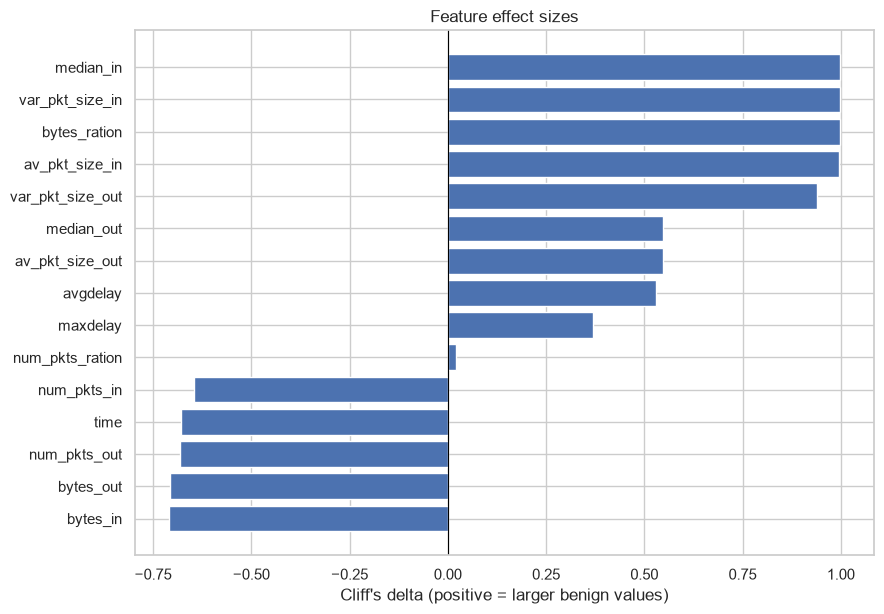

In [18]:
ranked = results.sort_values("cliffs_delta")
fig, ax = plt.subplots(figsize=(9, max(5, len(ranked) * 0.42)))
ax.barh(ranked["feature"], ranked["cliffs_delta"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Cliff's delta (positive = larger benign values)", title="Feature effect sizes")
plt.tight_layout()
plt.show()

### Interpretation: Effect-Size Analysis

Cliff's delta summarizes the direction and magnitude of differences. Positive values indicate that benign observations tend to have larger feature values; negative values indicate that malicious observations tend to have larger values.

The previously saved results showed very large positive effects for `median_in` (≈ 0.99898), `var_pkt_size_in` (≈ 0.99862), `bytes_ration` (≈ 0.99818), and `av_pkt_size_in` (≈ 0.99538). `bytes_in` (≈ −0.71017) and `bytes_out` (≈ −0.70749) had large negative effects. These results highlight incoming packet-size characteristics, ratios, and traffic volume as promising **descriptive** differences for these two subsets; they do not establish detection performance.

## 4. Feature redundancy check

Some feature statistics can match because the features are highly related or because their rank ordering is identical. In particular, the saved analysis gave matching U statistics and Cliff's delta for `av_pkt_size_out` and `median_out`. The checks below distinguish **exactly identical columns** from **highly correlated columns**. Matching test statistics alone do not prove the columns are identical.

In [19]:
pair = ("av_pkt_size_out", "median_out")
if all(column in df.columns for column in pair):
    a = pd.to_numeric(df[pair[0]], errors="coerce")
    b = pd.to_numeric(df[pair[1]], errors="coerce")
    print("Exactly equal (including missing-value positions):", a.equals(b))
    print("Spearman correlation:", a.corr(b, method="spearman"))
    print("Rows with unequal values:", int((~(a.eq(b) | (a.isna() & b.isna()))).sum()))
else:
    print("One or both features are absent; redundancy check skipped.")

Exactly equal (including missing-value positions): False
Spearman correlation: 0.9999992573760957
Rows with unequal values: 8320


## 5. Export results

In [20]:
output_dir = Path.cwd() / "results"
output_dir.mkdir(exist_ok=True)
results.to_csv(output_dir / "statistical_feature_comparison.csv", index=False)
print("Saved:", output_dir / "statistical_feature_comparison.csv")

Saved: /Users/yoelwoldeyes/Downloads/CS746_DoH_Traffic_Analysis/results/statistical_feature_comparison.csv


## 6. Discussion and limitations

### Interpretation: Findings and Limitations

The previously saved analysis identified statistically significant differences in 14 of 15 evaluated features after FDR adjustment. Large effects were especially apparent in incoming packet-size statistics, byte ratios, and traffic-volume measurements. This complements the exploratory analysis, but the study does not train or evaluate a classifier.

These observations are restricted to the selected Cloudflare and DNSCat2 traffic subsets. Network flows from the same capture or session may not be independent, and collection settings, endpoints, tools, or traffic-generation procedures may confound class comparisons. Multiple-testing correction does not eliminate these limitations. Feature units and any normalization in the source CSVs should be verified before assigning physical-unit interpretations. The results should not be generalized to all DoH traffic without independent datasets and validation.